# 식물 성장 단계 객체 탐지: 데이터 누수 방지부터 YOLO 평가까지

이 노트북은 Roboflow 데이터셋을 내려받고, 원본을 변경하지 않은 채
`germination`, `vegetative`, `flowering` 세 클래스만 남긴 정제 데이터셋을 만듭니다.
파일명 시퀀스를 1차 그룹 기준으로 사용하고 pHash를 보조 검증으로 사용합니다.

실행 순서는 다음과 같습니다.

1. 환경과 경로 설정
2. Roboflow 원본 데이터 다운로드
3. 파일명 패턴 분석 및 이미지·라벨 무결성 검사
4. 파일명 시퀀스 그룹 생성
5. pHash 확정 중복 병합 및 검토 대상 보고
6. 연결 컴포넌트 단위 재분할과 `cleaned_dataset/` 생성
7. 정제 전후 통계와 샘플 라벨 확인
8. YOLO 학습, val 검증, test 최종 평가와 추론
9. 최종 산출물과 누수 불변 조건 검증

> **중요:** test split은 학습이나 모델 선택에 사용하지 않습니다. 학습 중에는 val만
> 사용하며, test는 `best.pt`가 확정된 뒤 최종 평가에만 한 번 사용합니다.


## 0. 설치

새 JupyterLab 환경에서는 아래 셀의 주석을 해제해 의존성을 설치한 뒤 커널을 다시
시작하세요. CUDA용 PyTorch가 별도로 필요한 환경이라면 PyTorch 공식 설치 명령을
먼저 사용한 후 나머지 패키지를 설치하는 편이 안전합니다.


In [1]:
# 필요할 때만 주석을 해제해 실행하세요.
# %pip install -r requirements.txt


## 1. 설정

경로, 분할 비율, seed, 파일명 정규식, pHash 임계값과 YOLO 하이퍼파라미터는
모두 이 셀에서 바꿀 수 있습니다. 기본 정규식은 Roboflow 증강 해시, 증강 표식,
`frame/img/image` 번호, 날짜·시각 뒤 프레임 번호, 끝 숫자 토큰을 제거합니다.

실제 파일명 분석 셀의 결과를 확인한 뒤 데이터셋 고유 식별자가 지워지지 않도록
`SEQUENCE_PATTERNS`를 조정하세요. 규칙이 지나치게 넓으면 서로 다른 식물이 같은
시퀀스로 묶일 수 있습니다.


In [2]:
import os
import re
import json
import math
import random
import shutil
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from dotenv import load_dotenv
from PIL import Image, ImageDraw
from IPython.display import display
from tqdm.auto import tqdm

# 모든 상대 경로는 이 노트북을 실행하는 디렉터리를 기준으로 합니다.
PROJECT_ROOT = Path.cwd().resolve()
# 로컬 .env가 있으면 API 키를 환경변수로 읽되 기존 환경변수를 덮어쓰지 않습니다.
load_dotenv(PROJECT_ROOT / ".env", override=False)
RAW_DATASET_DIR = PROJECT_ROOT / "raw_dataset"
CLEAN_DATASET_DIR = PROJECT_ROOT / "cleaned_dataset"
REPORT_PATH = PROJECT_ROOT / "leakage_report.csv"
STATS_DIR = PROJECT_ROOT / "dataset_statistics"
RUNS_DIR = PROJECT_ROOT / "runs"
BEST_PT_PATH = PROJECT_ROOT / "best.pt"

ROBOFLOW_WORKSPACE = "general-plant-growth-stage-detection-model"
ROBOFLOW_PROJECT = "general-plant-growth-stage-model"
ROBOFLOW_VERSION = 2
ROBOFLOW_FORMAT = "yolov8"

TARGET_CLASSES = ["germination", "vegetative", "flowering"]
SPLIT_RATIOS = {"train": 0.70, "val": 0.20, "test": 0.10}
SEED = 42

# 실제 파일명 표본을 확인하고 필요하면 이 목록을 수정하세요.
SEQUENCE_PATTERNS = [
    r"(?i)(?:[._-]?rf[._-]?[0-9a-f]{8,})$", # Roboflow 계열 해시 접미사
    r"(?i)(?:[_-](?:aug|copy|rot(?:ate)?|flip|crop)(?:[_-]?\w+)*)$",
    r"(?i)(?:[_-](?:frame|img|image)[_-]?\d+)$",
    r"(?i)(?:[_-](?:jpg|jpeg|png))$",          # stem에 남은 원본 확장자 표식
    r"(?i)(?<=\d{8})[_-]\d{4,}$",           # 날짜 뒤 시각/프레임
    r"(?:[_-]\d{3,})$",                     # 말단의 긴 프레임 번호
]

PHASH_DUPLICATE_MAX = 5
PHASH_REVIEW_MIN = 6
PHASH_REVIEW_MAX = 10
PHASH_SIZE = 8
LARGE_COMPONENT_WARNING = 50

YOLO_MODEL = "yolo11n.pt"
EPOCHS = 10
IMAGE_SIZE = 640
BATCH_SIZE = 16
PATIENCE = 15
WORKERS = 4
CONFIDENCE = 0.25
SAMPLE_COUNT = 6
RUN_NAME = "plant_growth_yolo_quick10"

assert set(SPLIT_RATIOS) == {"train", "val", "test"}
assert math.isclose(sum(SPLIT_RATIOS.values()), 1.0, abs_tol=1e-9), \
    "SPLIT_RATIOS의 합은 1이어야 합니다."
assert all(value > 0 for value in SPLIT_RATIOS.values()), \
    "각 split 비율은 0보다 커야 합니다."
assert 0 <= PHASH_DUPLICATE_MAX < PHASH_REVIEW_MIN <= PHASH_REVIEW_MAX, \
    "pHash 임계값의 순서가 올바르지 않습니다."

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = 0
    print(f"CUDA 사용: {torch.cuda.get_device_name(0)}")
else:
    DEVICE = "cpu"
    print("CUDA를 사용할 수 없어 CPU로 실행합니다.")

print(f"프로젝트 경로: {PROJECT_ROOT}")
print(f"정제 데이터 경로: {CLEAN_DATASET_DIR}")


CUDA 사용: Tesla V100S-PCIE-32GB
프로젝트 경로: /home/j-i15e104
정제 데이터 경로: /home/j-i15e104/cleaned_dataset


## 2. Roboflow 원본 데이터 다운로드

API 키는 코드에 저장하지 않고 `ROBOFLOW_API_KEY` 환경변수에서만 읽습니다.
JupyterLab을 시작하기 전에 운영체제 셸에서 환경변수를 설정하세요.

```bash
export ROBOFLOW_API_KEY="발급받은_키"
jupyter lab
```

다운로드가 이미 완료되어 `raw_dataset/data.yaml`이 있으면 네트워크 호출을
건너뜁니다. 이후 셀은 원본 디렉터리에서 읽기만 하며 수정·이동·삭제하지 않습니다.


In [3]:
from roboflow import Roboflow

api_key = os.getenv("ROBOFLOW_API_KEY")
if not api_key:
    raise EnvironmentError(
        "ROBOFLOW_API_KEY 환경변수가 없습니다. 키를 설정하고 커널을 다시 시작하세요."
    )

raw_yaml = RAW_DATASET_DIR / "data.yaml"
if raw_yaml.exists():
    print(f"기존 원본 데이터 사용: {RAW_DATASET_DIR}")
else:
    rf = Roboflow(api_key=api_key)
    project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    version = project.version(ROBOFLOW_VERSION)
    downloaded = version.download(
        ROBOFLOW_FORMAT,
        location=str(RAW_DATASET_DIR),
        overwrite=False,
    )
    raw_yaml = Path(downloaded.location) / "data.yaml"
    print(f"다운로드 완료: {downloaded.location}")

if not raw_yaml.exists():
    candidates = list(RAW_DATASET_DIR.rglob("data.yaml"))
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"원본 data.yaml을 하나로 결정할 수 없습니다: {candidates}"
        )
    raw_yaml = candidates[0]
RAW_ROOT = raw_yaml.parent.resolve()
print(f"원본 YAML: {raw_yaml}")


기존 원본 데이터 사용: /home/j-i15e104/raw_dataset
원본 YAML: /home/j-i15e104/raw_dataset/data.yaml


## 3. 데이터 구조와 실제 파일명 패턴 분석

Roboflow YAML은 `valid` 디렉터리를 사용하면서 YAML 키는 `val`인 경우가 있습니다.
아래 함수는 YAML에 기록된 경로를 우선 해석하고, 없을 때 표준 디렉터리를 찾습니다.

파일명 그룹화 전에 실제 stem 표본과 토큰 빈도를 출력합니다. `원본 → 시퀀스 키`
표와 큰 그룹을 반드시 확인하세요. 패턴이 불명확하면 앞의 설정 셀에서 정규식을
고친 다음 이 셀부터 다시 실행합니다.


In [4]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def normalize_names(names):
    if isinstance(names, list):
        return {index: str(name).strip().lower() for index, name in enumerate(names)}
    return {int(index): str(name).strip().lower() for index, name in names.items()}

def resolve_yaml_path(value, yaml_dir):
    path = Path(str(value))
    if path.is_absolute():
        return path
    candidate = (yaml_dir / path).resolve()
    return candidate

def resolve_image_dir(config, split, dataset_root):
    aliases = [split]
    if split == "val":
        aliases.append("valid")
    value = config.get(split)
    if value:
        path = resolve_yaml_path(value, dataset_root)
        if path.exists():
            return path
    for alias in aliases:
        for path in [dataset_root / alias / "images", dataset_root / "images" / alias]:
            if path.exists():
                return path.resolve()
    raise FileNotFoundError(f"{split} 이미지 디렉터리를 찾을 수 없습니다.")

def label_dir_for(image_dir):
    if image_dir.name == "images":
        return image_dir.parent / "labels"
    parts = list(image_dir.parts)
    if "images" in parts:
        index = len(parts) - 1 - parts[::-1].index("images")
        parts[index] = "labels"
        return Path(*parts)
    return image_dir.parent / "labels"

empty_sequence_key_stems = set()

def make_sequence_key(stem):
    key = stem.lower()
    for pattern in SEQUENCE_PATTERNS:
        key = re.sub(pattern, "", key)
    key = re.sub(r"[-_.]+", "_", key).strip("_")
    # 빈 키는 한 그룹으로 합치지 않고 원래 stem으로 되돌리며 경고 대상을 기록합니다.
    if not key:
        empty_sequence_key_stems.add(stem)
        return stem.lower()
    return key

with raw_yaml.open(encoding="utf-8") as file:
    raw_config = yaml.safe_load(file)
original_names = normalize_names(raw_config["names"])
print("원본 클래스:", original_names)

# YOLO YAML의 path가 있으면 split 상대 경로의 기준으로 우선 사용합니다.
dataset_root_value = raw_config.get("path", ".")
dataset_root = resolve_yaml_path(dataset_root_value, RAW_ROOT)
if not dataset_root.exists():
    raise FileNotFoundError(f"YAML path 기준 디렉터리가 없습니다: {dataset_root}")
split_dirs = {
    split: resolve_image_dir(raw_config, split, dataset_root)
    for split in SPLIT_RATIOS
}
split_label_dirs = {split: label_dir_for(path) for split, path in split_dirs.items()}

discovered = []
for split, image_dir in split_dirs.items():
    images = sorted(
        path for path in image_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    print(f"{split:>5}: 이미지 {len(images):>6}개 | {image_dir}")
    discovered.extend((split, path) for path in images)

stems = [path.stem for _, path in discovered]
token_counts = Counter(
    token.lower()
    for stem in stems
    for token in re.split(r"[-_.]+", stem)
    if token
)
pattern_preview = pd.DataFrame(
    [{"원본_stem": stem, "시퀀스_키": make_sequence_key(stem)} for stem in stems[:30]]
)
display(pattern_preview)
print("자주 등장하는 파일명 토큰:", token_counts.most_common(30))

preview_groups = Counter(make_sequence_key(stem) for stem in stems)
display(
    pd.DataFrame(preview_groups.most_common(20), columns=["시퀀스_키", "이미지_수"])
)
if empty_sequence_key_stems:
    warnings.warn(
        f"정규화 후 키가 비어 원래 stem으로 복구한 파일이 "
        f"{len(empty_sequence_key_stems)}개 있습니다. 정규식을 검토하세요."
    )
if preview_groups and max(preview_groups.values()) >= LARGE_COMPONENT_WARNING:
    warnings.warn(
        "매우 큰 파일명 시퀀스 그룹이 있습니다. 정규식이 과도하지 않은지 확인하세요."
    )


원본 클래스: {0: 'flowering', 1: 'germination', 2: 'harvesting', 3: 'no detection', 4: 'vegetative'}


train: 이미지  20967개 | /home/j-i15e104/raw_dataset/train/images
  val: 이미지   1997개 | /home/j-i15e104/raw_dataset/valid/images
 test: 이미지    999개 | /home/j-i15e104/raw_dataset/test/images


,원본_stem,시퀀스_키
0,20210402104347-Urban_jpg.rf.59e6b305c4ce55bea7...,20210402104347_urban
1,20210402104347-Urban_jpg.rf.a0a70dc7d9bc0aeeac...,20210402104347_urban
2,20210402104347-Urban_jpg.rf.d080db2589bfa312a7...,20210402104347_urban
3,20210402110433-Urban_jpg.rf.6cd90224c48e3c4928...,20210402110433_urban
4,20210402110433-Urban_jpg.rf.c7ef4f4150a063e82b...,20210402110433_urban
5,20210402110433-Urban_jpg.rf.f0cfdb4aff6338846c...,20210402110433_urban
6,20210402110519-Urban_jpg.rf.37469a2ba85a8e80e3...,20210402110519_urban
7,20210402110519-Urban_jpg.rf.3d4ff3adafb93e2f6f...,20210402110519_urban
8,20210402110519-Urban_jpg.rf.50d50ac01b137acc99...,20210402110519_urban
9,20210402110605-Urban_jpg.rf.6d8d0cbbdc23c61cff...,20210402110605_urban


자주 등장하는 파일명 토큰: [('rf', 23963), ('jpg', 18394), ('90', 10788), ('weed', 5766), ('png', 5569), ('crop', 5012), ('heading', 4585), ('w1', 3384), ('pigweed', 2165), ('w0', 1900), ('roadside', 1742), ('of2', 1625), ('bean', 1567), ('aug', 1440), ('peanut', 1191), ('bf2', 1172), ('w2', 1137), ('w4', 1065), ('w3', 1037), ('1152', 1031), ('864', 1029), ('goosefoot', 1026), ('str3', 1007), ('grassland', 963), ('green', 846), ('gram', 846), ('red', 845), ('sesame', 831), ('str4', 781), ('henbit', 769)]


,시퀀스_키,이미지_수
0,crop_red_bean_w1_90,345
1,crop_peanut_w1_90,321
2,crop_bean_w1_90,270
3,weed_livid_pigweed_w1_90,267
4,weed_korean_dock_w0_90,265
5,weed_livid_pigweed_w0_90,262
6,weed_redroot_pigweed_w1_90,255
7,weed_henbit_w0_90,249
8,weed_henbit_w1_90,247
9,weed_smooth_pigweed_w0_90,247


매우 큰 파일명 시퀀스 그룹이 있습니다. 정규식이 과도하지 않은지 확인하세요.


## 4. 이미지·라벨 무결성 검사와 클래스 재매핑

각 이미지가 열리는지, 대응 라벨이 있는지, YOLO 라벨이 정확히 5개 값으로
구성되는지, 클래스와 정규화 좌표가 유효한지 검사합니다. 라벨만 존재하는 고아
파일도 별도로 찾습니다.

제외 클래스의 박스는 제거합니다. 세 대상 클래스의 박스가 하나도 남지 않는
이미지는 정제본에 포함하지 않고 제외 이유를 보고서에 남깁니다.


In [5]:
target_lookup = {name: index for index, name in enumerate(TARGET_CLASSES)}
class_remap = {
    old_id: target_lookup[name]
    for old_id, name in original_names.items()
    if name in target_lookup
}
missing_classes = set(TARGET_CLASSES) - set(original_names.values())
if missing_classes:
    raise ValueError(f"원본 데이터에 필요한 클래스가 없습니다: {sorted(missing_classes)}")
print("클래스 ID 재매핑:", class_remap)

audit_records = []
valid_records = []
seen_label_paths = set()

def audit(kind, status, reason, **kwargs):
    row = {"record_type": kind, "status": status, "reason": reason}
    row.update(kwargs)
    audit_records.append(row)

def parse_and_remap_label(label_path):
    remapped = []
    with label_path.open(encoding="utf-8") as file:
        for line_number, raw_line in enumerate(file, start=1):
            parts = raw_line.split()
            if len(parts) != 5:
                raise ValueError(f"{line_number}행의 값 개수가 5가 아닙니다.")
            try:
                old_class = int(parts[0])
                values = [float(value) for value in parts[1:]]
            except ValueError as error:
                raise ValueError(f"{line_number}행을 숫자로 변환할 수 없습니다.") from error
            if old_class not in original_names:
                raise ValueError(f"{line_number}행의 클래스 ID {old_class}가 없습니다.")
            x, y, width, height = values
            if not all(math.isfinite(value) for value in values):
                raise ValueError(f"{line_number}행에 유한하지 않은 좌표가 있습니다.")
            if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < width <= 1 and 0 < height <= 1):
                raise ValueError(f"{line_number}행의 정규화 좌표 범위가 잘못됐습니다.")
            if not (
                0 <= x - width / 2 <= x + width / 2 <= 1
                and 0 <= y - height / 2 <= y + height / 2 <= 1
            ):
                raise ValueError(f"{line_number}행의 박스가 이미지 경계를 벗어납니다.")
            if old_class in class_remap:
                remapped.append((class_remap[old_class], x, y, width, height))
    return remapped

for split, image_path in tqdm(discovered, desc="무결성 검사"):
    relative = image_path.relative_to(split_dirs[split])
    label_path = (split_label_dirs[split] / relative).with_suffix(".txt")
    base = {
        "image_path": str(image_path),
        "label_path": str(label_path),
        "original_split": split,
        "sequence_key": make_sequence_key(image_path.stem),
    }
    if not label_path.exists():
        audit("integrity", "excluded", "missing_label", **base)
        continue
    seen_label_paths.add(label_path.resolve())
    try:
        with Image.open(image_path) as image:
            image.verify()
        remapped = parse_and_remap_label(label_path)
    except Exception as error:
        reason = "corrupt_image_or_invalid_label"
        audit("integrity", "excluded", f"{reason}: {error}", **base)
        continue
    if not remapped:
        audit("class_filter", "excluded", "no_target_boxes", **base)
        continue
    class_ids = sorted({row[0] for row in remapped})
    valid_records.append(
        {
            **base,
            "image_path": image_path.resolve(),
            "label_path": label_path.resolve(),
            "boxes": remapped,
            "class_ids": class_ids,
        }
    )

for split, label_dir in split_label_dirs.items():
    if not label_dir.exists():
        continue
    for label_path in label_dir.rglob("*.txt"):
        if label_path.resolve() not in seen_label_paths:
            audit(
                "integrity",
                "excluded",
                "orphan_label",
                label_path=str(label_path.resolve()),
                original_split=split,
            )

if not valid_records:
    raise RuntimeError("무결성 및 클래스 필터링 후 남은 이미지가 없습니다.")
print(f"유효 이미지: {len(valid_records):,}개")
print(f"제외/경고 기록: {len(audit_records):,}개")
if audit_records:
    display(pd.DataFrame(audit_records)["reason"].value_counts().head(20))
else:
    print("무결성 검사에서 제외된 항목이 없습니다.")


클래스 ID 재매핑: {0: 2, 1: 0, 4: 1}


무결성 검사:   0%|          | 0/23963 [00:00<?, ?it/s]

유효 이미지: 17,179개
제외/경고 기록: 6,784개


reason
no_target_boxes    6784
Name: count, dtype: int64

## 5. pHash 계산과 확정 중복 연결 컴포넌트

pHash는 시각적으로 가까운 이미지를 찾는 보조 기준입니다. 해밍 거리 5 이하는
파일명 시퀀스 그룹끼리 병합하고, 6~10은 자동 병합하지 않고 검토 대상으로만
`leakage_report.csv`에 기록합니다.

BK-tree를 사용해 최대 거리 10 이내 후보만 찾습니다. 연결 컴포넌트는 전이적이므로
A≈B, B≈C이면 A와 C의 직접 거리가 멀어도 같은 컴포넌트가 될 수 있습니다.
이를 확인하도록 크기, 확정 pHash 간선의 최소·최대 거리, 간선 수와 병합 근거를
함께 집계합니다.


In [6]:
class UnionFind:
    def __init__(self, size):
        self.parent = list(range(size))
        self.rank = [0] * size

    def find(self, item):
        while self.parent[item] != item:
            self.parent[item] = self.parent[self.parent[item]]
            item = self.parent[item]
        return item

    def union(self, left, right):
        left_root, right_root = self.find(left), self.find(right)
        if left_root == right_root:
            return
        if self.rank[left_root] < self.rank[right_root]:
            left_root, right_root = right_root, left_root
        self.parent[right_root] = left_root
        if self.rank[left_root] == self.rank[right_root]:
            self.rank[left_root] += 1

class BKTree:
    def __init__(self):
        self.root = None

    def add(self, value, index):
        node = (value, index, {})
        if self.root is None:
            self.root = node
            return
        current = self.root
        while True:
            distance = (value ^ current[0]).bit_count()
            child = current[2].get(distance)
            if child is None:
                current[2][distance] = node
                return
            current = child

    def search(self, value, maximum):
        if self.root is None:
            return []
        matches, stack = [], [self.root]
        while stack:
            node_value, index, children = stack.pop()
            distance = (value ^ node_value).bit_count()
            if distance <= maximum:
                matches.append((distance, index))
            lower, upper = distance - maximum, distance + maximum
            stack.extend(
                child for edge, child in children.items() if lower <= edge <= upper
            )
        return matches

for record in tqdm(valid_records, desc="pHash 계산"):
    with Image.open(record["image_path"]) as image:
        hash_object = imagehash.phash(image.convert("RGB"), hash_size=PHASH_SIZE)
    record["phash"] = str(hash_object)
    record["phash_int"] = int(str(hash_object), 16)

union_find = UnionFind(len(valid_records))
sequence_members = defaultdict(list)
for index, record in enumerate(valid_records):
    sequence_members[record["sequence_key"]].append(index)

sequence_edges = []
for sequence_key, members in sequence_members.items():
    anchor = members[0]
    for member in members[1:]:
        union_find.union(anchor, member)
        sequence_edges.append((anchor, member, sequence_key))

duplicate_edges = []
review_pairs = []
tree = BKTree()
for index, record in enumerate(tqdm(valid_records, desc="pHash 후보 검색")):
    for distance, other_index in tree.search(record["phash_int"], PHASH_REVIEW_MAX):
        pair = (other_index, index, distance)
        if distance <= PHASH_DUPLICATE_MAX:
            union_find.union(other_index, index)
            duplicate_edges.append(pair)
        elif PHASH_REVIEW_MIN <= distance <= PHASH_REVIEW_MAX:
            review_pairs.append(pair)
    tree.add(record["phash_int"], index)

roots = [union_find.find(index) for index in range(len(valid_records))]
root_members = defaultdict(list)
for index, root in enumerate(roots):
    root_members[root].append(index)
ordered_roots = sorted(root_members, key=lambda root: min(root_members[root]))
component_ids = {root: f"component_{number:06d}" for number, root in enumerate(ordered_roots)}

component_duplicate_distances = defaultdict(list)
component_phash_edges = Counter()
for left, right, distance in duplicate_edges:
    root = union_find.find(left)
    component_duplicate_distances[root].append(distance)
    component_phash_edges[root] += 1
component_sequence_edges = Counter(union_find.find(left) for left, _, _ in sequence_edges)

component_stats = {}
for root, members in root_members.items():
    distances = component_duplicate_distances[root]
    reasons = []
    if component_sequence_edges[root]:
        reasons.append("filename_sequence")
    if component_phash_edges[root]:
        reasons.append("phash_confirmed")
    component_stats[root] = {
        "component_id": component_ids[root],
        "component_size": len(members),
        "component_min_phash_distance": min(distances) if distances else np.nan,
        "component_max_phash_distance": max(distances) if distances else np.nan,
        "sequence_edge_count": component_sequence_edges[root],
        "phash_edge_count": component_phash_edges[root],
        "merge_evidence": "+".join(reasons) if reasons else "singleton",
    }
    for member in members:
        valid_records[member].update(component_stats[root])
        valid_records[member]["component_root"] = root

component_table = pd.DataFrame(component_stats.values()).sort_values(
    "component_size", ascending=False
)
display(component_table.head(30))
component_size_distribution = (
    component_table.groupby("component_size", as_index=False)
    .size()
    .rename(columns={"size": "component_count"})
    .sort_values("component_size")
)
print("연결 컴포넌트 크기 분포")
display(component_size_distribution)
if not component_table.empty and component_table.iloc[0]["component_size"] >= LARGE_COMPONENT_WARNING:
    warnings.warn(
        "큰 연결 컴포넌트가 있습니다. 최대 pHash 거리와 병합 근거를 검토하세요."
    )
print(f"확정 pHash 간선: {len(duplicate_edges):,}개")
print(f"검토 대상 pHash 쌍: {len(review_pairs):,}개")


pHash 계산:   0%|          | 0/17179 [00:00<?, ?it/s]

pHash 후보 검색:   0%|          | 0/17179 [00:00<?, ?it/s]

,component_id,component_size,component_min_phash_distance,component_max_phash_distance,sequence_edge_count,phash_edge_count,merge_evidence
1872,component_001872,2846,0.0,4.0,2829,1213,filename_sequence+phash_confirmed
1870,component_001870,2002,0.0,4.0,1982,1660,filename_sequence+phash_confirmed
1804,component_001804,345,4.0,4.0,344,1,filename_sequence+phash_confirmed
1874,component_001874,341,0.0,4.0,339,116,filename_sequence+phash_confirmed
1783,component_001783,321,NaN,NaN,320,0,filename_sequence
1761,component_001761,270,NaN,NaN,269,0,filename_sequence
1771,component_001771,220,NaN,NaN,219,0,filename_sequence
1777,component_001777,210,NaN,NaN,209,0,filename_sequence
1794,component_001794,165,NaN,NaN,164,0,filename_sequence
1814,component_001814,154,NaN,NaN,153,0,filename_sequence


연결 컴포넌트 크기 분포


,component_size,component_count
0,1,760
1,2,6
2,3,1734
3,4,18
4,5,2
...,...,...
71,321,1
72,341,1
73,345,1
74,2002,1


확정 pHash 간선: 3,355개
검토 대상 pHash 쌍: 46,845개


큰 연결 컴포넌트가 있습니다. 최대 pHash 거리와 병합 근거를 검토하세요.


## 6. 컴포넌트 단위 재분할과 정제 데이터 생성

전체 재분할은 확정 중복 병합이 끝난 뒤 수행합니다. 연결 컴포넌트를 절대 쪼개지
않으며, 고정 seed로 동률 순서를 정합니다. 목적 함수는 split별 전체 이미지 수와
클래스별 이미지 수가 목표 비율에 가까워지도록 구성했습니다.

기존 `cleaned_dataset/`은 원본이 아니므로 재실행 시 교체합니다. 이미지 파일은
복사하고 라벨은 새 클래스 ID로 작성합니다. 원본 다운로드 디렉터리에는 어떠한
변경도 하지 않습니다.


In [7]:
def assign_components(records):
    components = defaultdict(list)
    for index, record in enumerate(records):
        components[record["component_root"]].append(index)

    total_images = len(records)
    total_classes = np.zeros(len(TARGET_CLASSES), dtype=float)
    component_rows = []
    for root, members in components.items():
        class_counts = np.zeros(len(TARGET_CLASSES), dtype=float)
        for member in members:
            class_counts[records[member]["class_ids"]] += 1
        total_classes += class_counts
        component_rows.append(
            {"root": root, "members": members, "size": len(members), "classes": class_counts}
        )

    rng = random.Random(SEED)
    rng.shuffle(component_rows)
    component_rows.sort(
        key=lambda row: (row["size"], row["classes"].max()), reverse=True
    )
    current_images = Counter()
    current_classes = {
        split: np.zeros(len(TARGET_CLASSES), dtype=float) for split in SPLIT_RATIOS
    }
    assignments = {}

    for row in component_rows:
        scores = {}
        for candidate in SPLIT_RATIOS:
            global_error = 0.0
            for split, ratio in SPLIT_RATIOS.items():
                image_target = max(total_images * ratio, 1.0)
                projected_images = current_images[split]
                projected_classes = current_classes[split]
                if split == candidate:
                    projected_images += row["size"]
                    projected_classes = projected_classes + row["classes"]
                image_error = ((projected_images - image_target) / total_images) ** 2
                class_target = np.maximum(total_classes * ratio, 1.0)
                class_error = np.mean(
                    ((projected_classes - class_target) / np.maximum(total_classes, 1.0)) ** 2
                )
                global_error += image_error + class_error
            scores[candidate] = global_error
        chosen = min(scores, key=lambda split: (scores[split], split))
        assignments[row["root"]] = chosen
        current_images[chosen] += row["size"]
        current_classes[chosen] += row["classes"]

    if any(current_images[split] == 0 for split in SPLIT_RATIOS):
        raise RuntimeError(
            "그룹 제약 때문에 빈 split이 생겼습니다. 비율 또는 그룹화 정규식을 검토하세요."
        )
    return assignments

assignments = assign_components(valid_records)
for record in valid_records:
    record["clean_split"] = assignments[record["component_root"]]

# 각 split의 클래스 존재 여부를 학습 전에 진단합니다.
for split in SPLIT_RATIOS:
    present = {
        class_id
        for record in valid_records if record["clean_split"] == split
        for class_id in record["class_ids"]
    }
    absent = [TARGET_CLASSES[class_id] for class_id in range(len(TARGET_CLASSES)) if class_id not in present]
    if absent:
        warnings.warn(
            f"{split} split에 없는 클래스가 있습니다: {absent}. "
            "그룹 제약과 데이터 수를 확인하세요. 해당 평가 지표는 NaN으로 표시됩니다."
        )

# 설정 오류가 원본 삭제·수정을 일으키지 않도록 양방향 경로 중첩을 차단합니다.
raw_resolved = RAW_ROOT.resolve()
clean_resolved = CLEAN_DATASET_DIR.resolve()
paths_overlap = (
    clean_resolved == raw_resolved
    or clean_resolved.is_relative_to(raw_resolved)
    or raw_resolved.is_relative_to(clean_resolved)
)
if paths_overlap:
    raise ValueError(
        f"CLEAN_DATASET_DIR({clean_resolved})와 원본({raw_resolved})은 "
        "같거나 서로 포함하는 경로일 수 없습니다."
    )
if CLEAN_DATASET_DIR.exists():
    shutil.rmtree(CLEAN_DATASET_DIR)
for split in SPLIT_RATIOS:
    (CLEAN_DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (CLEAN_DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

used_names = set()
for index, record in enumerate(tqdm(valid_records, desc="정제 데이터 복사")):
    # stem 충돌을 방지하면서 원래 stem을 사람이 알아볼 수 있게 보존합니다.
    safe_stem = re.sub(r"[^0-9A-Za-z가-힣_-]+", "_", record["image_path"].stem)
    new_stem = f"{index:07d}_{safe_stem}"
    while new_stem in used_names:
        new_stem += "_x"
    used_names.add(new_stem)
    split = record["clean_split"]
    destination_image = (
        CLEAN_DATASET_DIR / "images" / split / f"{new_stem}{record['image_path'].suffix.lower()}"
    )
    destination_label = CLEAN_DATASET_DIR / "labels" / split / f"{new_stem}.txt"
    shutil.copy2(record["image_path"], destination_image)
    label_text = "\n".join(
        f"{class_id} {x:.8f} {y:.8f} {width:.8f} {height:.8f}"
        for class_id, x, y, width, height in record["boxes"]
    )
    destination_label.write_text(label_text + "\n", encoding="utf-8")
    record["clean_image_path"] = destination_image.resolve()
    record["clean_label_path"] = destination_label.resolve()
    if split != record["original_split"]:
        audit(
            "split_assignment",
            "moved_group",
            "component_level_repartition",
            image_path=str(record["image_path"]),
            original_split=record["original_split"],
            clean_split=split,
            sequence_key=record["sequence_key"],
            **component_stats[record["component_root"]],
        )

clean_yaml = CLEAN_DATASET_DIR / "data.yaml"
clean_config = {
    "path": str(CLEAN_DATASET_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(TARGET_CLASSES),
    "names": {index: name for index, name in enumerate(TARGET_CLASSES)},
}
clean_yaml.write_text(
    yaml.safe_dump(clean_config, sort_keys=False, allow_unicode=True),
    encoding="utf-8",
)
print(f"정제 데이터셋 생성 완료: {CLEAN_DATASET_DIR}")


정제 데이터 복사:   0%|          | 0/17179 [00:00<?, ?it/s]

정제 데이터셋 생성 완료: /home/j-i15e104/cleaned_dataset


## 7. 누수 보고서와 정제 전후 통계

보고서는 무결성 제외, 그룹 단위 이동, 확정 pHash 쌍, 검토 대상 pHash 쌍을 모두
포함합니다. 각 레코드에는 가능한 경우 컴포넌트 크기, 거리 범위와 병합 근거가
들어갑니다.

`before_statistics.csv`는 대상 클래스 필터링을 통과한 이미지를 원래 split 기준으로,
`after_statistics.csv`는 정제 split 기준으로 집계합니다. 이미지 수, 클래스별
이미지 수와 박스 수, 전체 대비 split 비율을 함께 출력합니다.


In [8]:
# 모든 유효 이미지를 컴포넌트 구성원 레코드로 남겨 추적 가능하게 합니다.
for record in valid_records:
    audit(
        "component_membership",
        "included",
        "valid_image_component_membership",
        image_path=str(record["image_path"]),
        label_path=str(record["label_path"]),
        original_split=record["original_split"],
        clean_split=record["clean_split"],
        sequence_key=record["sequence_key"],
        **component_stats[record["component_root"]],
    )

for left, right, distance in duplicate_edges:
    left_record, right_record = valid_records[left], valid_records[right]
    root = left_record["component_root"]
    audit(
        "phash_pair",
        "confirmed_duplicate",
        "phash_distance_at_or_below_duplicate_threshold",
        image_path=str(left_record["image_path"]),
        compared_image_path=str(right_record["image_path"]),
        original_split=left_record["original_split"],
        compared_original_split=right_record["original_split"],
        clean_split=left_record["clean_split"],
        sequence_key=left_record["sequence_key"],
        compared_sequence_key=right_record["sequence_key"],
        phash_distance=distance,
        **component_stats[root],
    )

for left, right, distance in review_pairs:
    left_record, right_record = valid_records[left], valid_records[right]
    audit(
        "phash_pair",
        "review_required",
        "phash_distance_in_review_range_no_auto_move",
        image_path=str(left_record["image_path"]),
        compared_image_path=str(right_record["image_path"]),
        original_split=left_record["original_split"],
        compared_original_split=right_record["original_split"],
        clean_split=left_record["clean_split"],
        compared_clean_split=right_record["clean_split"],
        sequence_key=left_record["sequence_key"],
        compared_sequence_key=right_record["sequence_key"],
        phash_distance=distance,
        component_id=left_record["component_id"],
        compared_component_id=right_record["component_id"],
        component_size=left_record["component_size"],
        compared_component_size=right_record["component_size"],
        component_min_phash_distance=left_record["component_min_phash_distance"],
        component_max_phash_distance=left_record["component_max_phash_distance"],
        sequence_edge_count=left_record["sequence_edge_count"],
        phash_edge_count=left_record["phash_edge_count"],
        merge_evidence=left_record["merge_evidence"],
        compared_component_min_phash_distance=right_record["component_min_phash_distance"],
        compared_component_max_phash_distance=right_record["component_max_phash_distance"],
        compared_sequence_edge_count=right_record["sequence_edge_count"],
        compared_phash_edge_count=right_record["phash_edge_count"],
        compared_merge_evidence=right_record["merge_evidence"],
    )

report_columns = [
    "record_type", "status", "reason", "image_path", "label_path",
    "compared_image_path", "original_split", "compared_original_split",
    "clean_split", "compared_clean_split", "sequence_key",
    "compared_sequence_key", "phash_distance", "component_id",
    "compared_component_id", "component_size",
    "component_min_phash_distance", "component_max_phash_distance",
    "sequence_edge_count", "phash_edge_count", "merge_evidence",
    "compared_component_size", "compared_component_min_phash_distance",
    "compared_component_max_phash_distance", "compared_sequence_edge_count",
    "compared_phash_edge_count", "compared_merge_evidence",
]
report_df = pd.DataFrame(audit_records)
for column in report_columns:
    if column not in report_df:
        report_df[column] = np.nan
report_df[report_columns].to_csv(REPORT_PATH, index=False, encoding="utf-8-sig")
print(f"누수 보고서 저장: {REPORT_PATH} ({len(report_df):,}행)")

def build_statistics(records, split_field):
    rows = []
    total = len(records)
    for split in SPLIT_RATIOS:
        subset = [record for record in records if record[split_field] == split]
        base = {
            "split": split,
            "class": "__all__",
            "image_count": len(subset),
            "box_count": sum(len(record["boxes"]) for record in subset),
            "split_ratio": len(subset) / total if total else 0,
        }
        rows.append(base)
        for class_id, class_name in enumerate(TARGET_CLASSES):
            rows.append(
                {
                    "split": split,
                    "class": class_name,
                    "image_count": sum(class_id in record["class_ids"] for record in subset),
                    "box_count": sum(
                        box[0] == class_id
                        for record in subset
                        for box in record["boxes"]
                    ),
                    "split_ratio": len(subset) / total if total else 0,
                }
            )
    return pd.DataFrame(rows)

STATS_DIR.mkdir(parents=True, exist_ok=True)
before_stats = build_statistics(valid_records, "original_split")
after_stats = build_statistics(valid_records, "clean_split")
before_stats.to_csv(STATS_DIR / "before_statistics.csv", index=False, encoding="utf-8-sig")
after_stats.to_csv(STATS_DIR / "after_statistics.csv", index=False, encoding="utf-8-sig")
component_table.to_csv(
    STATS_DIR / "component_statistics.csv", index=False, encoding="utf-8-sig"
)
component_size_distribution.to_csv(
    STATS_DIR / "component_size_distribution.csv", index=False, encoding="utf-8-sig"
)

print("정제 전 통계")
display(before_stats)
print("정제 후 통계")
display(after_stats)


누수 보고서 저장: /home/j-i15e104/leakage_report.csv (80,074행)
정제 전 통계


,split,class,image_count,box_count,split_ratio
0,train,__all__,15037,22468,0.875313
1,train,germination,5295,5439,0.875313
2,train,vegetative,5167,9724,0.875313
3,train,flowering,4578,7305,0.875313
4,val,__all__,1428,2199,0.083125
5,val,germination,507,516,0.083125
6,val,vegetative,489,985,0.083125
7,val,flowering,433,698,0.083125
8,test,__all__,714,1144,0.041562
9,test,germination,252,274,0.041562


정제 후 통계


,split,class,image_count,box_count,split_ratio
0,train,__all__,12346,16010,0.718668
1,train,germination,4759,4759,0.718668
2,train,vegetative,4017,5782,0.718668
3,train,flowering,3570,5469,0.718668
4,val,__all__,3275,6432,0.190640
5,val,germination,951,1025,0.190640
6,val,vegetative,1237,3507,0.190640
7,val,flowering,1091,1900,0.190640
8,test,__all__,1558,3369,0.090692
9,test,germination,344,445,0.090692


## 8. 정제 라벨 샘플 시각화

정제된 YOLO 라벨을 직접 읽어 이미지 위에 표시합니다. 색상은 클래스마다 고정이며,
박스와 클래스명이 올바른지 학습 전에 확인할 수 있습니다.


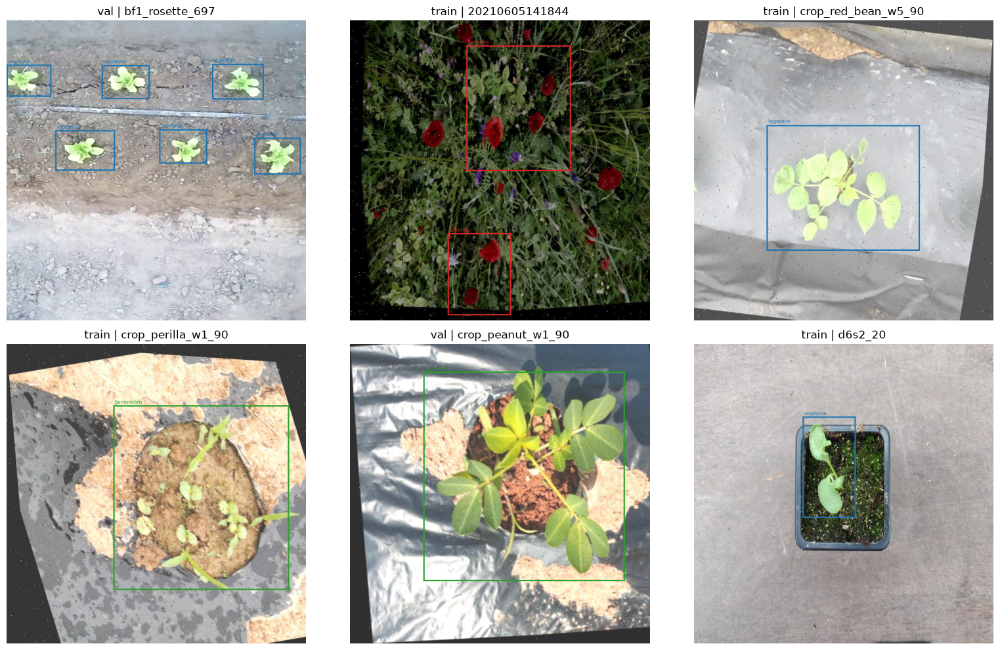

In [9]:
CLASS_COLORS = ["#2ca02c", "#1f77b4", "#d62728"]

def draw_yolo_sample(record):
    image = Image.open(record["clean_image_path"]).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size
    for class_id, x, y, box_width, box_height in record["boxes"]:
        left = (x - box_width / 2) * width
        top = (y - box_height / 2) * height
        right = (x + box_width / 2) * width
        bottom = (y + box_height / 2) * height
        color = CLASS_COLORS[class_id]
        draw.rectangle((left, top, right, bottom), outline=color, width=3)
        draw.text((left + 3, max(0, top - 14)), TARGET_CLASSES[class_id], fill=color)
    return image

sample_rng = random.Random(SEED)
sample_records = sample_rng.sample(valid_records, min(SAMPLE_COUNT, len(valid_records)))
columns = 3
rows = math.ceil(len(sample_records) / columns)
figure, axes = plt.subplots(rows, columns, figsize=(16, 5 * rows))
axes = np.atleast_1d(axes).ravel()
for axis, record in zip(axes, sample_records):
    axis.imshow(draw_yolo_sample(record))
    axis.set_title(f"{record['clean_split']} | {record['sequence_key']}")
    axis.axis("off")
for axis in axes[len(sample_records):]:
    axis.axis("off")
plt.tight_layout()
plt.show()


## 9. Ultralytics YOLO 학습

학습에는 `cleaned_dataset/data.yaml`의 train과 val만 사용됩니다. Ultralytics는
val 지표를 기준으로 가장 좋은 체크포인트를 저장합니다. test는 이 단계에서
호출하지 않습니다.


In [10]:
from ultralytics import YOLO

model = YOLO(YOLO_MODEL)
train_results = model.train(
    data=str(clean_yaml),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    workers=WORKERS,
    device=DEVICE,
    seed=SEED,
    deterministic=True,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
)

training_best = Path(model.trainer.best)
if not training_best.exists():
    raise FileNotFoundError(f"학습 best 가중치를 찾을 수 없습니다: {training_best}")
shutil.copy2(training_best, BEST_PT_PATH)
print(f"최고 가중치 별도 저장: {BEST_PT_PATH}")


New https://pypi.org/project/ultralytics/8.4.105 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.104 🚀 Python-3.12.6 torch-2.5.1+cu121 CUDA:0 (Tesla V100S-PCIE-32GB, 32494MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/j-i15e104/cleaned_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=plant_growth_yolo_quick10, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=15, per

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


...

            vegetative       1237       3507      0.683      0.954      0.879      0.575


             flowering       1091       1900      0.488      0.499      0.454      0.203


Speed: 0.1ms preprocess, 0.7ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/j-i15e104/runs/plant_growth_yolo_quick10


최고 가중치 별도 저장: /home/j-i15e104/best.pt


## 10. val 검증: 클래스별 Precision·Recall·mAP와 혼동행렬

아래 결과는 모델 선택에 사용한 val split의 상세 지표입니다. 클래스별
Precision, Recall, mAP50, mAP50-95를 표로 출력하고 Ultralytics가 저장한
혼동행렬을 표시합니다.


Ultralytics 8.4.104 🚀 Python-3.12.6 torch-2.5.1+cu121 CUDA:0 (Tesla V100S-PCIE-32GB, 32494MiB)


YOLO11n summary (fused): 101 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2594.2±374.7 MB/s, size: 93.4 KB)


val: Scanning /home/j-i15e104/cleaned_dataset/labels/val.cache... 3275 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3275/3275 1.4Git/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 1/205 1.3it/s 0.2s<2:41

...

            vegetative       1237       3507      0.683      0.954      0.878      0.575


             flowering       1091       1900      0.487      0.498      0.454      0.203


Speed: 0.7ms preprocess, 1.2ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/j-i15e104/runs/plant_growth_yolo_quick10_val-2


,class,Precision,Recall,mAP50,mAP50-95
0,germination,0.7550,0.4302,0.5827,0.3452
1,vegetative,0.6828,0.9544,0.8784,0.5746
2,flowering,0.4867,0.4979,0.4536,0.2026


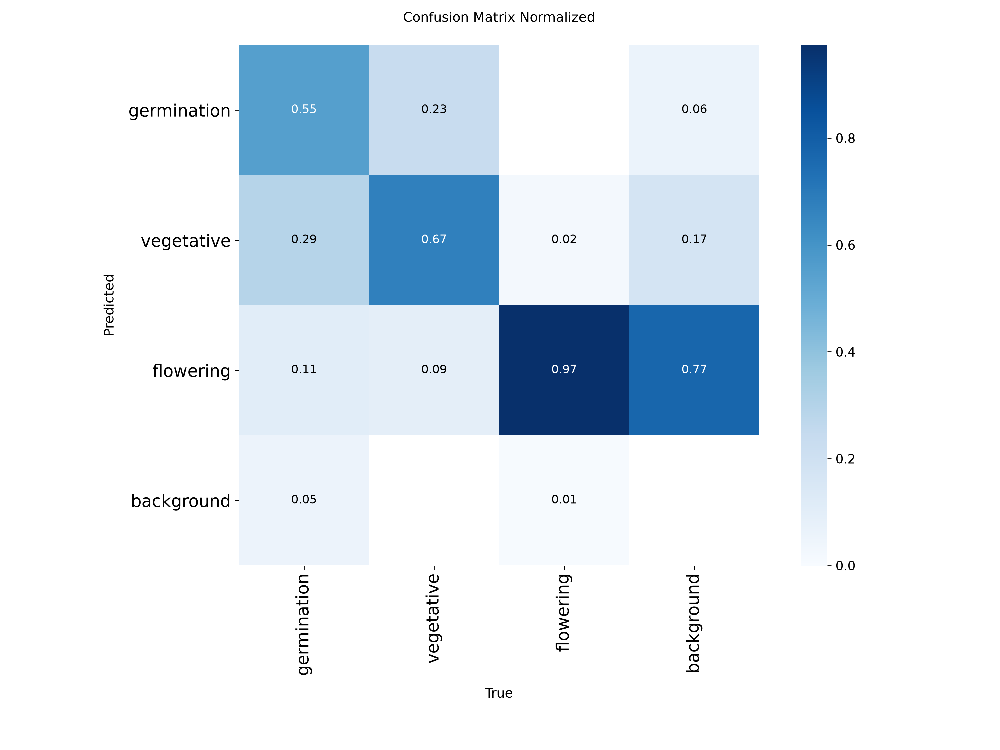

In [11]:
best_model = YOLO(str(BEST_PT_PATH))
val_metrics = best_model.val(
    data=str(clean_yaml),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}_val",
    plots=True,
)

def per_class_metrics_table(metrics):
    # Ultralytics 배열은 전체 클래스 ID가 아니라 ap_class_index 순서입니다.
    evaluated_ids = [int(value) for value in metrics.box.ap_class_index]
    position_by_class = {
        class_id: position for position, class_id in enumerate(evaluated_ids)
    }
    rows = []
    for class_id, class_name in enumerate(TARGET_CLASSES):
        position = position_by_class.get(class_id)
        if position is None:
            warnings.warn(
                f"평가 split에 {class_name} 정답이 없어 지표를 NaN으로 표시합니다."
            )
            values = [np.nan] * 4
        else:
            values = [
                float(metrics.box.p[position]),
                float(metrics.box.r[position]),
                float(metrics.box.ap50[position]),
                float(metrics.box.ap[position]),
            ]
        rows.append(
            dict(
                zip(
                    ["class", "Precision", "Recall", "mAP50", "mAP50-95"],
                    [class_name, *values],
                )
            )
        )
    return pd.DataFrame(rows)

val_class_metrics = per_class_metrics_table(val_metrics)
display(val_class_metrics.style.format({column: "{:.4f}" for column in val_class_metrics.columns[1:]}))
val_class_metrics.to_csv(
    STATS_DIR / "val_class_metrics.csv", index=False, encoding="utf-8-sig"
)

confusion_candidates = [
    Path(val_metrics.save_dir) / "confusion_matrix_normalized.png",
    Path(val_metrics.save_dir) / "confusion_matrix.png",
]
confusion_path = next((path for path in confusion_candidates if path.exists()), None)
if confusion_path:
    display(Image.open(confusion_path))
else:
    warnings.warn("저장된 혼동행렬 이미지를 찾지 못했습니다.")


## 11. test 최종 평가

이 셀에서 처음으로 test split을 사용합니다. 이미 확정된 `best.pt`를 변경하거나
하이퍼파라미터를 선택하는 데 test 결과를 사용하지 마세요.


In [12]:
test_metrics = best_model.val(
    data=str(clean_yaml),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}_test_final",
    plots=True,
)
test_class_metrics = per_class_metrics_table(test_metrics)
display(
    test_class_metrics.style.format(
        {column: "{:.4f}" for column in test_class_metrics.columns[1:]}
    )
)
test_class_metrics.to_csv(
    STATS_DIR / "test_class_metrics.csv", index=False, encoding="utf-8-sig"
)


Ultralytics 8.4.104 🚀 Python-3.12.6 torch-2.5.1+cu121 CUDA:0 (Tesla V100S-PCIE-32GB, 32494MiB)


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2574.8±345.4 MB/s, size: 86.8 KB)


val: Scanning /home/j-i15e104/cleaned_dataset/labels/test... 264 images, 0 backgrounds, 0 corrupt: 16% ━━────────── 264/1558 791.9it/s 0.1s<1.6s

val: Scanning /home/j-i15e104/cleaned_dataset/labels/test... 532 images, 0 backgrounds, 0 corrupt: 34% ━━━━──────── 532/1558 1.4Kit/s 0.2s<0.8s

val: Scanning /home/j-i15e104/cleaned_dataset/labels/test... 803 images, 0 backgrounds, 0 corrupt: 51% ━━━━━━────── 803/1558 1.8Kit/s 0.3s<0.4s

...

            vegetative        647       1937      0.611      0.949      0.836      0.531


             flowering        567        987      0.487       0.55      0.508      0.245


Speed: 0.8ms preprocess, 1.3ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /home/j-i15e104/runs/plant_growth_yolo_quick10_test_final-2


,class,Precision,Recall,mAP50,mAP50-95
0,germination,0.5800,0.0787,0.2256,0.0928
1,vegetative,0.6106,0.9489,0.8357,0.5306
2,flowering,0.4870,0.5502,0.5083,0.2448


## 12. test 이미지 추론과 바운딩 박스 시각화

고정 seed로 test 이미지 표본을 선택하고 `best.pt`의 예측 박스를 표시합니다.
박스 위에는 클래스명과 confidence가 함께 나타납니다.


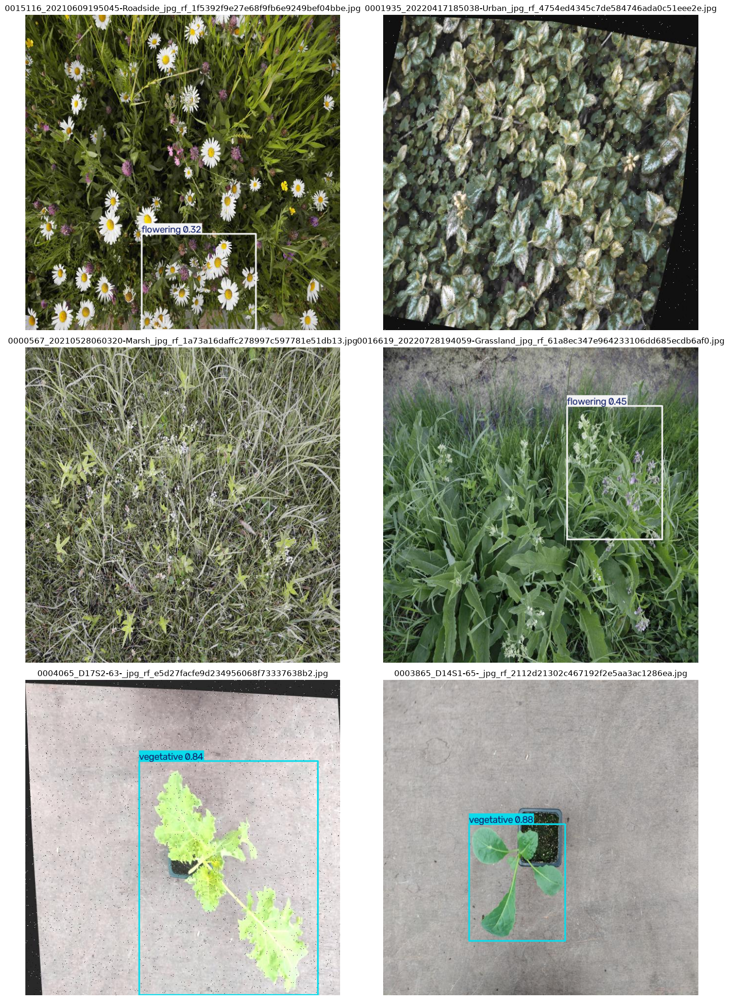

In [13]:
test_images = sorted((CLEAN_DATASET_DIR / "images" / "test").glob("*"))
if not test_images:
    raise RuntimeError("추론할 test 이미지가 없습니다.")
inference_rng = random.Random(SEED)
inference_paths = inference_rng.sample(test_images, min(SAMPLE_COUNT, len(test_images)))
predictions = best_model.predict(
    source=[str(path) for path in inference_paths],
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE,
    device=DEVICE,
    verbose=False,
)

columns = 2
rows = math.ceil(len(predictions) / columns)
figure, axes = plt.subplots(rows, columns, figsize=(16, 7 * rows))
axes = np.atleast_1d(axes).ravel()
for axis, prediction, path in zip(axes, predictions, inference_paths):
    plotted_bgr = prediction.plot()
    axis.imshow(plotted_bgr[..., ::-1])
    axis.set_title(path.name)
    axis.axis("off")
for axis in axes[len(predictions):]:
    axis.axis("off")
plt.tight_layout()
plt.show()


## 13. 최종 누수 및 산출물 검증

마지막 셀은 정제된 각 시퀀스와 확정 중복 컴포넌트가 하나의 split에만 있는지,
이미지와 라벨이 일대일인지, 필수 결과가 모두 생성되었는지 검사합니다.
하나라도 위반되면 성공 메시지 대신 예외가 발생합니다.


In [14]:
metadata_df = pd.DataFrame(
    [
        {
            "sequence_key": record["sequence_key"],
            "component_id": record["component_id"],
            "clean_split": record["clean_split"],
            "clean_image_path": str(record["clean_image_path"]),
        }
        for record in valid_records
    ]
)
sequence_split_counts = metadata_df.groupby("sequence_key")["clean_split"].nunique()
component_split_counts = metadata_df.groupby("component_id")["clean_split"].nunique()
assert sequence_split_counts.max() == 1, "한 시퀀스가 둘 이상의 split에 있습니다."
assert component_split_counts.max() == 1, "한 중복 컴포넌트가 둘 이상의 split에 있습니다."

for split in SPLIT_RATIOS:
    image_dir = CLEAN_DATASET_DIR / "images" / split
    label_dir = CLEAN_DATASET_DIR / "labels" / split
    image_stems = {
        path.stem for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    }
    label_stems = {path.stem for path in label_dir.glob("*.txt")}
    assert image_stems == label_stems, (
        f"{split}의 이미지·라벨 stem이 일치하지 않습니다. "
        f"이미지만: {image_stems-label_stems}, 라벨만: {label_stems-image_stems}"
    )
    assert image_stems, f"{split} split이 비어 있습니다."

required_outputs = [
    CLEAN_DATASET_DIR / "data.yaml",
    REPORT_PATH,
    STATS_DIR / "before_statistics.csv",
    STATS_DIR / "after_statistics.csv",
    STATS_DIR / "component_statistics.csv",
    STATS_DIR / "component_size_distribution.csv",
    STATS_DIR / "val_class_metrics.csv",
    STATS_DIR / "test_class_metrics.csv",
    BEST_PT_PATH,
]
missing_outputs = [path for path in required_outputs if not path.exists()]
assert not missing_outputs, f"생성되지 않은 필수 산출물: {missing_outputs}"

print("cleaned_dataset 구조")
for path in sorted(CLEAN_DATASET_DIR.rglob("*")):
    if path.is_dir():
        count = sum(1 for child in path.iterdir() if child.is_file())
        print(f"- {path.relative_to(PROJECT_ROOT)}/ ({count}개 파일)")
print(f"- {REPORT_PATH.relative_to(PROJECT_ROOT)}")
print(f"- {STATS_DIR.relative_to(PROJECT_ROOT)}/")
print(f"- {BEST_PT_PATH.relative_to(PROJECT_ROOT)}")
print("최종 검증 통과: 시퀀스/중복 그룹 누수 없음, 필수 산출물 생성 완료")


cleaned_dataset 구조


- cleaned_dataset/images/ (0개 파일)
- cleaned_dataset/images/test/ (1558개 파일)
- cleaned_dataset/images/train/ (12346개 파일)
- cleaned_dataset/images/val/ (3275개 파일)
- cleaned_dataset/labels/ (3개 파일)
- cleaned_dataset/labels/test/ (1558개 파일)
- cleaned_dataset/labels/train/ (12346개 파일)


- cleaned_dataset/labels/val/ (3275개 파일)
- leakage_report.csv
- dataset_statistics/
- best.pt
최종 검증 통과: 시퀀스/중복 그룹 누수 없음, 필수 산출물 생성 완료
